In [33]:
from article_utils.util import read_jsonl

df = read_jsonl('admin.seqlabel.labelled.jsonl.gz')
df['row_index'] = df.index.tolist()
df = df.explode('label')
df['label.start'] = df.label.str[0]
df['label.end'] = df.label.str[1]
df['label.name'] = df.label.str[-1]
df['generation_config'] = df.filepath.str.extract(r'gen-(\d+)')
df['model_dir'] = df.filepath.str.split(' ').str[8]
df['model'] = df.model_dir.str.split('__').str[1]
df['label'] = df['label.name'].str.split(':').str[0].apply(lambda x: x if x not in {'Poor/confusing wording/grammar', 'Poor formatting'} else 'confusing')
df = df.sort_values(['label', 'model']).reset_index(drop=True)

print(df.columns)
print(df.filepath.unique())
df

Index(['id', 'text', 'Comments', 'abstract', 'accuracy', 'cat', 'civic.id',
       'claim.flat', 'contextHtml', 'document.pmcid', 'document.pmid',
       'evidence.flat', 'example.id', 'filepath', 'has_content', 'partition',
       'predicted_label_name', 'label', 'row_index', 'label.start',
       'label.end', 'label.name', 'generation_config', 'model_dir', 'model'],
      dtype='object')
['results claim_verification fine-tuning config-8 completion civicfact-2025.01.14 chat-default prompts.reason.0-shot.train.jsonl BioMistral__BioMistral-7B-DARE evaluations civicfactpairs-grand-bat-L5000-2024.12.22 chat-default gen-2 prompts.reason.0-shot.train.processed.jsonl.gz'
 'results claim_verification fine-tuning config-8 completion civicfact-2025.01.14 chat-default prompts.reason.0-shot.train.jsonl BioMistral__BioMistral-7B-DARE evaluations civicfactpairs-grand-bat-L5000-2024.12.22 chat-default gen-1 prompts.reason.0-shot.train.processed.jsonl.gz'
 'results claim_verification fine-tuning conf

,id,text,Comments,abstract,accuracy,cat,civic.id,claim.flat,contextHtml,document.pmcid,...,partition,predicted_label_name,label,row_index,label.start,label.end,label.name,generation_config,model_dir,model
0,[claim:644210_ev:672679_REFUTES_r0],label: NEI. There are no data presented. \nlab...,[],False,0.000000,"[Response - Irrelevant, Response - Poor gramma...",[10047],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2118656,...,train,NEI,claim-relevant,1,59.0,101.0,claim-relevant,2,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
1,[claim:644210_ev:672679_REFUTES_r0],label: NEI. There are no data presented. \nlab...,[],False,0.000000,"[Response - Irrelevant, Response - Poor gramma...",[10047],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2118656,...,train,NEI,claim-relevant,1,389.0,466.0,claim-relevant,2,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
2,[claim:644209_ev:672775_REFUTES_r0],label: GAIN of function. These experiments sup...,[],False,0.000000,"[Response - Major Errors (logic errors, invali...",[10046],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2118656,...,train,GAIN,claim-relevant,4,440.0,577.0,claim-relevant,2,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
3,[claim:640946_ev:660016_REFUTES_r0],label: SUPPORTS. PIK3CA mutations in the prima...,[],False,0.000000,"[Response - Major Errors (logic errors, invali...",[6299],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2720232,...,train,SUPPORTS,claim-relevant,11,17.0,118.0,claim-relevant,2,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
4,[claim:641032_ev:660073_SUPPORTS_r0],label: NEI. The specific BRAF mutation is not ...,[],False,0.000000,"[Gold Label Incorrect, Response - Poor grammar...",[6403],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2720232,...,train,NEI,claim-relevant,13,0.0,55.0,claim-relevant,1,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
834,[claim:643702_ev:672446_SUPPORTS_r0],label: SUPPORTS. Missing data. The paper uses ...,[],False,0.041667,[Response - Irrelevant],[9492],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2873663,...,dev,SUPPORTS,NaN,206,NaN,NaN,NaN,1,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
835,[claim:690662_ev:672260_SUPPORTS_r0],label: REFUTES. Several drugs have been develo...,[],False,0.083333,[Response - Irrelevant],[1353],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC4529334,...,dev,REFUTES,NaN,222,NaN,NaN,NaN,2,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
836,[claim:643706_ev:672782_SUPPORTS_r0],label: NEI. Several items needed removal befor...,[],False,0.166667,[Possible CIViC Error?],[9496],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2873663,...,dev,NEI,NaN,251,NaN,NaN,NaN,1,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE
837,[claim:643711_ev:672591_SUPPORTS_r0],label: SUPPORTS. Several conclusions can be dr...,[],False,0.250000,"[Gold Label Incorrect, Response - Irrelevant, ...",[9502],molecular profile\tevidence type\tsignificance...,"<div class=""example""><div class=""question""><h2...",PMC2873663,...,dev,SUPPORTS,NaN,344,NaN,NaN,NaN,1,BioMistral__BioMistral-7B-DARE,BioMistral-7B-DARE


In [34]:
total_rows = df.row_index.nunique()
print('total rows', total_rows)
stat_df = df.copy()
stat_df = stat_df.groupby(['label', 'model']).agg({'row_index': 'nunique'}).reset_index()
total_df = df.groupby(['model']).agg({'row_index': 'nunique'}).reset_index().rename(columns={'row_index': 'total'})
stat_df = stat_df.merge(total_df)
stat_df['freq'] = stat_df.row_index / stat_df.total
stat_df

total rows 367


,label,model,row_index,total,freq
0,claim-relevant,BioMistral-7B-DARE,84,183,0.459016
1,claim-relevant,Meta-Llama-3.1-8B-Instruct,114,184,0.619565
2,confusing,BioMistral-7B-DARE,45,183,0.245902
3,confusing,Meta-Llama-3.1-8B-Instruct,40,184,0.217391
4,contradicts evidence or claim,BioMistral-7B-DARE,76,183,0.415301
5,contradicts evidence or claim,Meta-Llama-3.1-8B-Instruct,95,184,0.516304
6,different claim,BioMistral-7B-DARE,25,183,0.136612
7,different claim,Meta-Llama-3.1-8B-Instruct,37,184,0.201087
8,logic error,BioMistral-7B-DARE,28,183,0.153005
9,logic error,Meta-Llama-3.1-8B-Instruct,47,184,0.255435


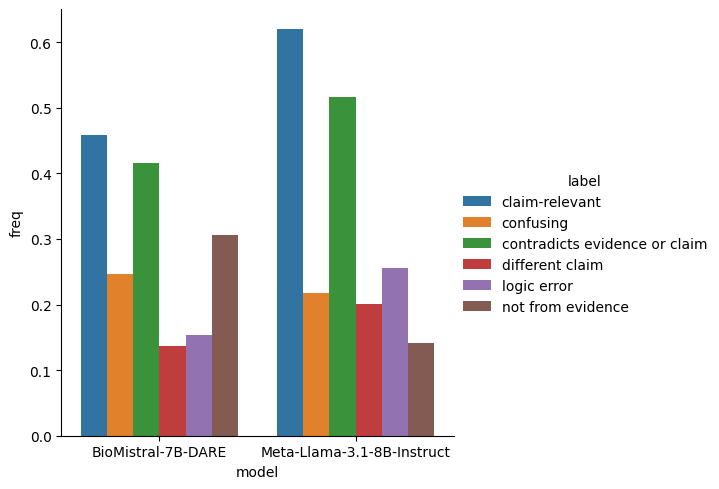

In [35]:
import seaborn as sns

sns.catplot(stat_df, x='model', y='freq', hue='label', kind='bar')

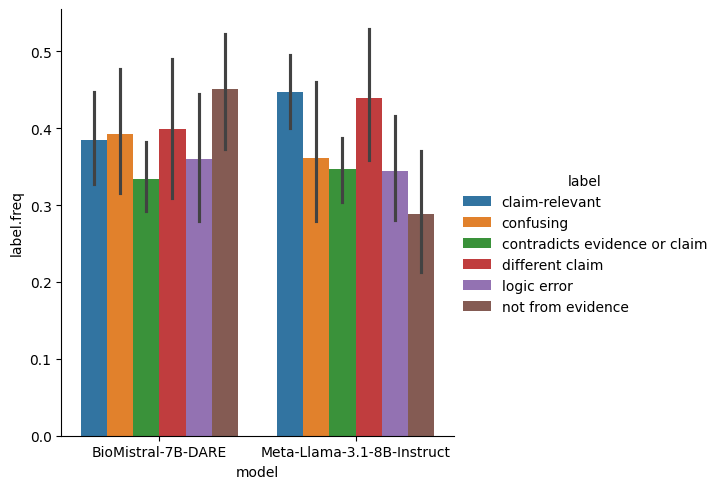

In [36]:
# per response percentages
import pandas as pd

total_rows = df['row_index'].nunique()

fig_df = df.copy()
fig_df['label.length'] = fig_df['label.end'] - fig_df['label.start']
fig_df['label.freq'] = fig_df['label.length'] / fig_df['text'].str.len()
fig_df = fig_df.groupby(['row_index', 'model', 'label']).agg({'label.freq': 'sum'}).reset_index()

empty_copy = fig_df.copy()
empty_copy['label.freq'] = 0

# add 0freq labels for all examples where they do not already have said label
fig_df = pd.concat([fig_df, empty_copy])
fig_df = fig_df.drop_duplicates(['label', 'row_index', 'model'], keep='first')
fig_df = fig_df.sort_values(['label', 'model'])
sns.catplot(fig_df, x='model', hue='label', y='label.freq', kind='bar')